In [20]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

## Setup
$80\%$ of the data is used for training (the functions $f_i$) and $20\%$ for testing.

Preprocessing (**log + clip**):
1. take the logarithm of the skewed features `AveRooms`, `AveBedrms`, `Population`, `AveOccup`;
2. standardize with the mean and the standard deviation of the training set;
3. clip every standardized feature to $[-3, 3]$;
4. add the constant feature $1$ (bias).

Without steps 1 and 3 a few districts with extreme features give $L_{\max} \approx 8600$ while $\bar L = 9$,
and the stepsize $\frac{1}{A} = \frac{1}{2L_{\max}}$ of the theory is useless (see the table below).

In [31]:
TEST_SIZE = 0.2
SEED = 0
LOG_FEATURES = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
CLIP = 3.0

data = fetch_california_housing()
FEATURES = data.feature_names + ["bias"]
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=TEST_SIZE, random_state=SEED)


def make_features(X_train, X_test, log=True, clip=CLIP):
    # log of the skewed features, standardize with the train statistics, clip, add bias
    log_idx = [data.feature_names.index(name) for name in LOG_FEATURES]

    def transform(X):
        X = X.copy()
        if log:
            X[:, log_idx] = np.log(X[:, log_idx])
        return X

    T_train, T_test = transform(X_train), transform(X_test)
    mean, std = T_train.mean(axis=0), T_train.std(axis=0)
    out = []
    for T in (T_train, T_test):
        Z = (T - mean) / std
        if clip is not None:
            Z = np.clip(Z, -clip, clip)
        out.append(np.hstack([Z, np.ones((len(Z), 1))]))
    return out


a_train, a_test = make_features(X_train, X_test)
N, D = a_train.shape
print(f"n = {N} training points, {len(a_test)} test points, d = {D}")

n = 16512 training points, 4128 test points, d = 9


## The functions
`i` can be one index or an array of indices, and `x` one point of shape `(d,)` or a batch of shape `(..., d)`
(e.g. one point per independent SGD run).

In [33]:
def f_i(a, y, i, x):
    # f_i(x) = 1/2 (<a_i, x> - y_i)^2
    return 0.5 * (np.einsum("...j,...j->...", a[i], x) - y[i]) ** 2


def grad_f_i(a, y, i, x):
    # grad f_i(x) = a_i (<a_i, x> - y_i)
    r = np.einsum("...j,...j->...", a[i], x) - y[i]
    return a[i] * r[..., None]


def f(a, y, x):
    # f(x) = 1/n sum_i f_i(x) = 1/(2n) ||Phi x - y||^2
    return 0.5 * np.mean((x @ a.T - y) ** 2, axis=-1)


def grad_f(a, y, x):
    # grad f(x) = 1/n Phi^T (Phi x - y)
    return (x @ a.T - y) @ a / len(y)

## Constants of the problem and test metrics

In [34]:
def constants(a, y):
    n = len(y)
    x_star = np.linalg.solve(a.T @ a, a.T @ y)
    L_i = np.sum(a ** 2, axis=1)                            # ||a_i||^2
    eig = np.linalg.eigvalsh(a.T @ a / n)
    G = grad_f_i(a, y, np.arange(n), x_star)                # rows: grad f_i(x*)
    sigma2 = np.mean(np.sum(G ** 2, axis=1))                # sigma_*^2
    return dict(x_star=x_star, f_star=f(a, y, x_star), L_i=L_i, L_max=L_i.max(), L_bar=L_i.mean(),
                L=eig[-1], mu=eig[0], A=2 * L_i.max(), C=2 * sigma2, sigma2=sigma2)


def mse(a, y, x):
    return np.mean((x @ a.T - y) ** 2, axis=-1)


def r2(a, y, x):
    return 1 - mse(a, y, x) / np.var(y)

Effect of the preprocessing (same split, same model):

In [35]:
print(f"{'features':12s} {'mu':>7s} {'L':>6s} {'L_bar':>6s} {'L_max':>8s} {'A':>8s} {'C':>7s} {'test MSE':>9s}")
for name, log, clip in [("raw", False, None), ("log", True, None), ("clip", False, CLIP), ("log + clip", True, CLIP)]:
    tr, te = make_features(X_train, X_test, log=log, clip=clip)
    k = constants(tr, y_train)
    print(f"{name:12s} {k['mu']:7.4f} {k['L']:6.3f} {k['L_bar']:6.2f} {k['L_max']:8.1f} {k['A']:8.1f} "
          f"{k['C']:7.3f} {mse(te, y_test, k['x_star']):9.4f}")

features          mu      L  L_bar    L_max        A       C  test MSE
raw           0.0447  2.024   9.00   8594.7  17189.4  72.142    0.5290
log           0.0509  2.084   9.00    610.2   1220.4  15.623    0.4501
clip          0.0212  1.962   6.00     32.7     65.3   6.001    0.4649
log + clip    0.0480  2.035   7.88     45.3     90.7   8.052    0.4290


The problem we use from now on (log + clip):

In [25]:
c = constants(a_train, y_train)
x_star, f_star, mu, L, A, C = c["x_star"], c["f_star"], c["mu"], c["L"], c["A"], c["C"]
print(f"mu = {mu:.4f}, L = {L:.4f}, L_bar = {c['L_bar']:.2f}, L_max = {c['L_max']:.2f}")
print(f"A = {A:.2f}, C = {C:.3f}, f* = {f_star:.4f}")
print(f"||grad f(x*)|| = {np.linalg.norm(grad_f(a_train, y_train, x_star)):.1e}")
print("x* =", ", ".join(f"{name} {v:+.4f}" for name, v in zip(FEATURES, x_star)))
MSE_TRAIN_STAR, MSE_TEST_STAR = mse(a_train, y_train, x_star), mse(a_test, y_test, x_star)
print(f"x*: train MSE {MSE_TRAIN_STAR:.4f}, test MSE {MSE_TEST_STAR:.4f}, "
      f"test R^2 {r2(a_test, y_test, x_star):.4f}")

mu = 0.0480, L = 2.0354, L_bar = 7.88, L_max = 45.33
A = 90.66, C = 8.052, f* = 0.2096
||grad f(x*)|| = 1.3e-14
x* = MedInc +0.9627, HouseAge +0.1593, AveRooms -0.2055, AveBedrms +0.2684, Population +0.0328, AveOccup -0.2858, Latitude -0.8074, Longitude -0.7489, bias +2.0958
x*: train MSE 0.4192, test MSE 0.4290, test R^2 0.6710


## Methods
All methods start from $x^0 = 0$. We measure the error $\|x^k - x^\star\|^2$ (for SGD: its mean over independent runs)
and the train / test MSE.

* **GD**: $x^{k+1} = x^k - \gamma_k\nabla f(x^k)$, either with a constant $\gamma_k = \frac{1}{L}$, or with the
  **Polyak stepsize** $\gamma_k = \frac{2D_f(x^k, x^\star)}{\|\nabla f(x^k) - \nabla f(x^\star)\|^2}$.
  Since $\nabla f(x^\star) = 0$, we have $D_f(x^k, x^\star) = f(x^k) - f^\star$, so
  $\gamma_k = \frac{2(f(x^k) - f^\star)}{\|\nabla f(x^k)\|^2}$.
* **SGD**: $x^{k+1} = x^k - \gamma\nabla f_{i_k}(x^k)$, $i_k \sim \mathrm{Uniform}\{1,\dots,n\}$, with a constant $\gamma$.

**Step count and time.** For every method we run single trajectories from $x^0 = 0$ and record the number of
steps, the number of gradient evaluations $\nabla f_i$ (one GD step costs $n$, one SGD step costs $1$) and the
wall-clock time until
* (err) $\|x^k - x^\star\|^2 \le 10^{-2}\|x^0 - x^\star\|^2$, and
* (test) test MSE $\le 1.1\cdot$ test MSE$(x^\star)$.

Only the update steps are timed (checking the criteria is not). SGD numbers are means over $5$ seeds.
Each experiment prints its own results, and all of them are collected in the table at the end.

In [26]:
X0 = np.zeros(D)
RUNS = 200        # independent SGD runs used to estimate E||x^k - x*||^2
TOL = 1e-8        # GD stops when ||x^k - x*||^2 <= TOL ||x^0 - x*||^2
R0 = np.sum((X0 - x_star) ** 2)
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def gd(stepsize, max_iters=5000, x0=X0, tol=TOL):
    # GD; stepsize(x, grad) -> gamma_k. Returns dict of per-iteration histories.
    x = x0.copy()
    hist = dict(err=[np.sum((x - x_star) ** 2)], gamma=[],
                train=[mse(a_train, y_train, x)], test=[mse(a_test, y_test, x)])
    t = 0.0
    for k in range(max_iters):
        t0 = time.perf_counter()
        g = grad_f(a_train, y_train, x)
        gamma = stepsize(x, g)
        x = x - gamma * g
        t += time.perf_counter() - t0
        hist.setdefault("time", []).append(t)
        hist["gamma"].append(gamma)
        hist["err"].append(np.sum((x - x_star) ** 2))
        hist["train"].append(mse(a_train, y_train, x))
        hist["test"].append(mse(a_test, y_test, x))
        if hist["err"][-1] <= tol * R0:
            break
    return {key: np.array(v) for key, v in hist.items()}


def gd_constant(gamma):
    return lambda x, g: gamma


def gd_polyak(x, g):
    # gamma_k = 2 (f(x^k) - f*) / ||grad f(x^k)||^2
    return 2 * (f(a_train, y_train, x) - f_star) / np.sum(g ** 2)


def sgd(stepsize, iters, runs=RUNS, x0=X0, seed=SEED, record=None):
    # `runs` independent copies of SGD; stepsize(i, x, g) -> gamma_k (one per run).
    # Returns E||x^k - x*||^2 for k = 0..iters, and (if record) the mean train/test MSE every `record` steps.
    rng = np.random.default_rng(seed + 1)
    x = np.tile(x0, (runs, 1))
    err = np.empty(iters + 1)
    err[0] = np.mean(np.sum((x - x_star) ** 2, axis=1))
    rec_k, rec_train, rec_test = [], [], []
    with np.errstate(over="ignore", invalid="ignore"):       # large stepsizes may diverge
        for k in range(iters + 1):
            if record and k % record == 0:
                rec_k.append(k)
                rec_train.append(mse(a_train, y_train, x).mean())
                rec_test.append(mse(a_test, y_test, x).mean())
            if k == iters:
                break
            i = rng.integers(0, N, size=runs)
            g = grad_f_i(a_train, y_train, i, x)
            x = x - stepsize(i, x, g)[:, None] * g
            err[k + 1] = np.mean(np.sum((x - x_star) ** 2, axis=1))
    return dict(err=err, x=x, k=np.array(rec_k), train=np.array(rec_train), test=np.array(rec_test))


def sgd_constant(gamma):
    return lambda i, x, g: np.full(len(i), gamma)


# --- step count and time -------------------------------------------------------
TOL_ERR = 1e-2    # (err):  ||x^k - x*||^2 <= TOL_ERR ||x^0 - x*||^2
TOL_TEST = 1.1    # (test): test MSE <= TOL_TEST * test MSE(x*)
SEEDS = 5
RESULTS = {}      # name -> {"err": (steps, grads, seconds) or None, "test": ...}


def gd_step(stepsize):
    def step(x, rng):
        g = grad_f(a_train, y_train, x)
        return x - stepsize(x, g) * g
    return step


def sgd_step(gamma):
    def step(x, rng):
        i = rng.integers(0, N)
        return x - gamma * grad_f_i(a_train, y_train, i, x)
    return step


def measure(name, step, stochastic, max_steps):
    # Single trajectories from X0; only step() is timed. Mean over SEEDS seeds for SGD.
    seeds = SEEDS if stochastic else 1
    hits = {"err": [], "test": []}
    for s in range(seeds):
        rng = np.random.default_rng(SEED + 100 + s)
        x, t, found = X0.copy(), 0.0, {}
        for k in range(1, max_steps + 1):
            t0 = time.perf_counter()
            x = step(x, rng)
            t += time.perf_counter() - t0
            if "err" not in found and np.sum((x - x_star) ** 2) <= TOL_ERR * R0:
                found["err"] = (k, t)
            if "test" not in found and mse(a_test, y_test, x) <= TOL_TEST * MSE_TEST_STAR:
                found["test"] = (k, t)
            if len(found) == 2:
                break
        for key in hits:
            hits[key].append(found.get(key))
    cost = 1 if stochastic else N
    res = {}
    for key, h in hits.items():
        if all(v is not None for v in h):            # reached in every seed
            steps, secs = np.mean([v[0] for v in h]), np.mean([v[1] for v in h])
            res[key] = (steps, steps * cost, secs)
        else:
            res[key] = None
    RESULTS[name] = res
    print(f"  {name:14s}" + "".join(f"  {key}: {fmt(res[key])}" for key in res))


def fmt(r):
    if r is None:
        return f"{'not reached':^43s}"
    steps, grads, secs = r
    return f"{steps:8.0f} steps, {grads:9.0f} grads, {1e3 * secs:7.1f} ms"


def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), dpi=150)
    plt.show()

## Experiment 1: GD with a constant stepsize
$\gamma = \frac{1}{L}$; bound (Theorem 15): $\|x^k - x^\star\|^2 \le \bigl(1 - \frac{\mu}{L}\bigr)^k\|x^0 - x^\star\|^2$.

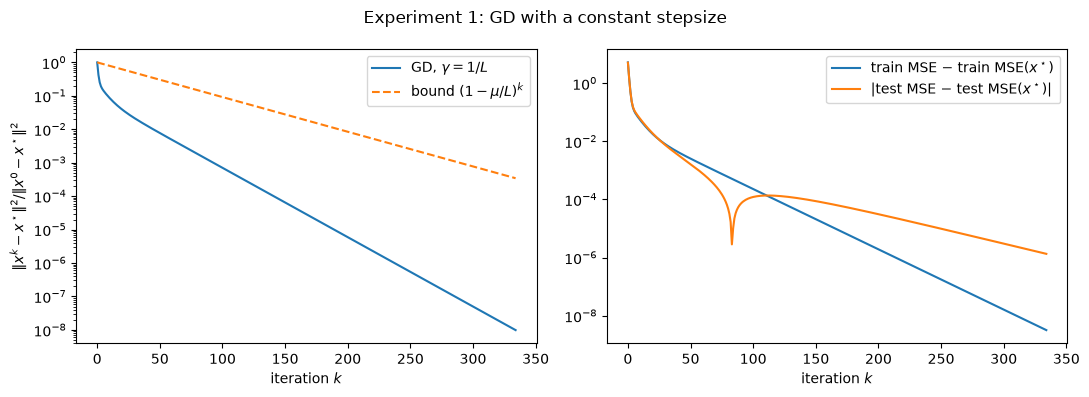

GD 1/L: 334 steps, 40.3 ms to reach ||x^k - x*||^2 <= 1e-08 ||x^0 - x*||^2 (theory: 781 steps); bound violated: False
  k =    0: train MSE 5.6336, test MSE 5.5179
  k =   10: train MSE 0.4721, test MSE 0.4866
  k =   50: train MSE 0.4218, test MSE 0.4306
  k =  100: train MSE 0.4194, test MSE 0.4288
  k =  334: train MSE 0.4192, test MSE 0.4290
Step count and time:
  GD, 1/L         err:       45 steps,    743040 grads,     6.9 ms  test:       13 steps,    214656 grads,     2.5 ms


In [27]:
gd_const = gd(gd_constant(1 / L))
k = np.arange(len(gd_const["err"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.semilogy(k, gd_const["err"] / R0, label=r"GD, $\gamma = 1/L$")
ax.semilogy(k, (1 - mu / L) ** k, "--", label=r"bound $(1-\mu/L)^k$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|x^k-x^\star\|^2 / \|x^0-x^\star\|^2$")
ax.legend()
ax = axes[1]
ax.semilogy(k, gd_const["train"] - MSE_TRAIN_STAR, label="train MSE $-$ train MSE$(x^\\star)$")
ax.semilogy(k, np.abs(gd_const["test"] - MSE_TEST_STAR), label="|test MSE $-$ test MSE$(x^\\star)$|")
ax.set_xlabel("iteration $k$")
ax.legend()
fig.suptitle("Experiment 1: GD with a constant stepsize")
save(fig, "cal_exp1_gd.png")

print(f"GD 1/L: {len(k) - 1} steps, {1e3 * gd_const['time'][-1]:.1f} ms to reach "
      f"||x^k - x*||^2 <= {TOL:g} ||x^0 - x*||^2 (theory: {np.log(1 / TOL) / (mu / L):.0f} steps); "
      f"bound violated: {np.any(gd_const['err'] / R0 > (1 - mu / L) ** k * (1 + 1e-9))}")
for kk in [0, 10, 50, 100, len(k) - 1]:
    print(f"  k = {kk:4d}: train MSE {gd_const['train'][kk]:.4f}, test MSE {gd_const['test'][kk]:.4f}")
print("Step count and time:")
measure("GD, 1/L", gd_step(gd_constant(1 / L)), stochastic=False, max_steps=5000)

## Experiment 2: GD with the Polyak stepsize
Checks: $\frac{1}{L} \le \gamma_k \le \frac{1}{\mu}$, and $\|x^{k+1} - x^\star\|^2 \le (1-\gamma_k\mu)\|x^k - x^\star\|^2$ at every step.
Dashed: the bound $\prod_{j<k}(1-\gamma_j\mu)\,\|x^0 - x^\star\|^2$.

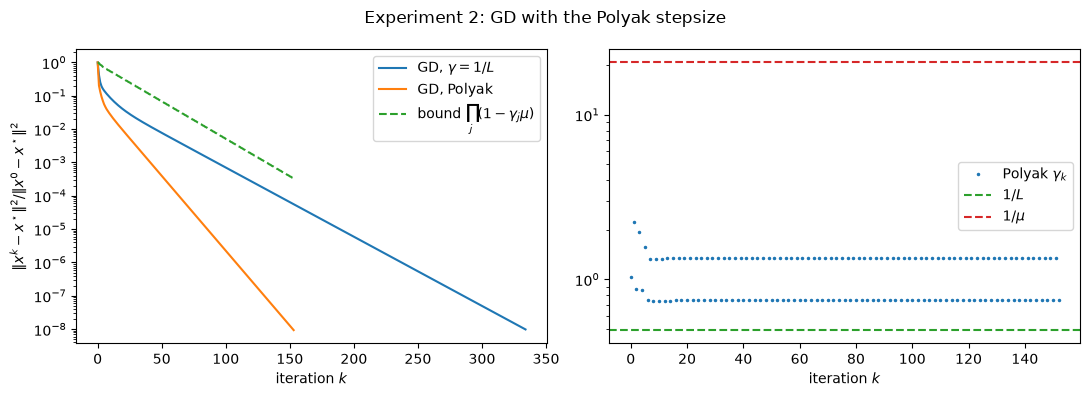

GD Polyak: 153 steps, 34.7 ms to reach the tolerance (GD 1/L: 334 steps, 40.3 ms)
gamma_k in [0.7369, 2.2422], 1/L = 0.4913, 1/mu = 20.8174; 1/L <= gamma_k <= 1/mu for all k: True
one-step bound holds for all k: True
final: train MSE 0.4192, test MSE 0.4290
Step count and time:
  GD, Polyak      err:       19 steps,    313728 grads,     4.9 ms  test:        7 steps,    115584 grads,     1.7 ms


In [28]:
gd_pol = gd(gd_polyak)
kp = np.arange(len(gd_pol["err"]))
gam = gd_pol["gamma"]
bound_pol = np.concatenate([[1.0], np.cumprod(1 - gam * mu)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.semilogy(k, gd_const["err"] / R0, label=r"GD, $\gamma = 1/L$")
ax.semilogy(kp, gd_pol["err"] / R0, label="GD, Polyak")
ax.semilogy(kp, bound_pol, "--", label=r"bound $\prod_j(1-\gamma_j\mu)$")
ax.set_xlabel("iteration $k$")
ax.set_ylabel(r"$\|x^k-x^\star\|^2 / \|x^0-x^\star\|^2$")
ax.legend()
ax = axes[1]
ax.plot(gam, ".", ms=3, label=r"Polyak $\gamma_k$")
ax.axhline(1 / L, ls="--", color="C2", label=r"$1/L$")
ax.axhline(1 / mu, ls="--", color="C3", label=r"$1/\mu$")
ax.set_yscale("log")
ax.set_xlabel("iteration $k$")
ax.legend()
fig.suptitle("Experiment 2: GD with the Polyak stepsize")
save(fig, "cal_exp2_polyak.png")

step_ok = gd_pol["err"][1:] <= (1 - gam * mu) * gd_pol["err"][:-1] * (1 + 1e-9)
print(f"GD Polyak: {len(kp) - 1} steps, {1e3 * gd_pol['time'][-1]:.1f} ms to reach the tolerance "
      f"(GD 1/L: {len(k) - 1} steps, {1e3 * gd_const['time'][-1]:.1f} ms)")
print(f"gamma_k in [{gam.min():.4f}, {gam.max():.4f}], 1/L = {1 / L:.4f}, 1/mu = {1 / mu:.4f}; "
      f"1/L <= gamma_k <= 1/mu for all k: {np.all((gam >= 1 / L * (1 - 1e-9)) & (gam <= 1 / mu * (1 + 1e-9)))}")
print(f"one-step bound holds for all k: {np.all(step_ok)}")
print(f"final: train MSE {gd_pol['train'][-1]:.4f}, test MSE {gd_pol['test'][-1]:.4f}")
print("Step count and time:")
measure("GD, Polyak", gd_step(gd_polyak), stochastic=False, max_steps=5000)

## Experiment 3: SGD with the AC constants
Theorem 33 with $A = 2L_{\max}$, $C = 2\sigma_\star^2$ (Exercise 29): for $0 < \gamma \le \frac{1}{A}$,
$\ \mathbb{E}\|x^k - x^\star\|^2 \le (1-\gamma\mu)^k\|x^0 - x^\star\|^2 + \frac{\gamma C}{\mu}$.

**3a.** $\gamma = \frac{1}{A}$ and the bound. **3b.** $\gamma = \frac{1}{mA}$, $m = 1, 2, 4$: the neighbourhood
is proportional to $\gamma$. **3c.** $\gamma = \frac{m}{A}$, $m = 1, 2, 4, 8, 16$: stepsizes larger than the theory allows.

3a: gamma = 1/A = 0.0110: plateau 0.0294, radius gamma C / mu = 1.8488, bound violated: False
3b: gamma = 1/(1A): plateau 0.0294, radius 1.8488, plateau * m = 0.0294, bound violated: False
3b: gamma = 1/(2A): plateau 0.0143, radius 0.9244, plateau * m = 0.0286, bound violated: False
3b: gamma = 1/(4A): plateau 0.0071, radius 0.4622, plateau * m = 0.0286, bound violated: False
3c: gamma = 1/A = 0.0110: plateau 0.0294, reaches 1.1 x plateau after 4835 steps
3c: gamma = 2/A = 0.0221: plateau 0.0627, reaches 1.1 x plateau after 1949 steps
3c: gamma = 4/A = 0.0441: plateau 0.1459, reaches 1.1 x plateau after 752 steps
3c: gamma = 8/A = 0.0882: plateau 0.4382, reaches 1.1 x plateau after 235 steps
3c: gamma = 16/A = 0.1765: does not converge (E||x^k - x*||^2 ends at 44.7 > ||x^0 - x*||^2 = 6.75)


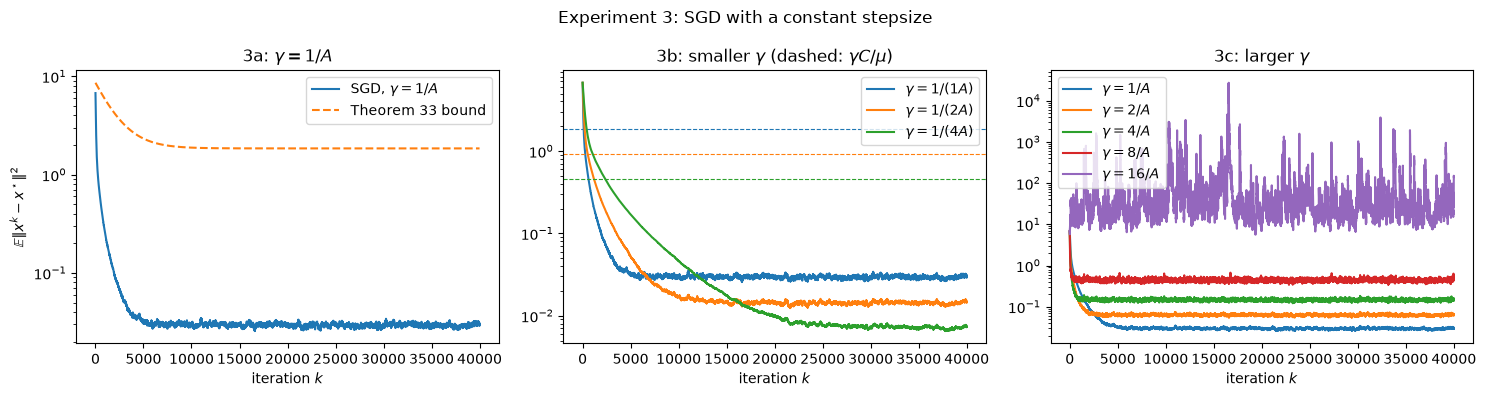

Step count and time (single runs, mean over seeds; at most 60000 steps):
  SGD, 1/(4A)     err:     8747 steps,      8747 grads,    73.9 ms  test:     2576 steps,      2576 grads,    23.1 ms
  SGD, 1/(2A)     err:     4564 steps,      4564 grads,    36.5 ms  test:     1281 steps,      1281 grads,    11.2 ms
  SGD, 1/A        err:     2162 steps,      2162 grads,    18.2 ms  test:      682 steps,       682 grads,     6.2 ms
  SGD, 2/A        err:     1067 steps,      1067 grads,    11.2 ms  test:      446 steps,       446 grads,     5.6 ms
  SGD, 4/A        err:      617 steps,       617 grads,     5.0 ms  test:      269 steps,       269 grads,     2.3 ms


In [29]:
ITERS = 40000
k3 = np.arange(ITERS + 1)

def bound33(gamma, k):
    return (1 - gamma * mu) ** k * R0 + gamma * C / mu

sgd_runs = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# 3a
gamma = 1 / A
run = sgd_runs[1.0] = sgd(sgd_constant(gamma), ITERS)
ax = axes[0]
ax.semilogy(run["err"], label=r"SGD, $\gamma = 1/A$")
ax.semilogy(bound33(gamma, k3), "--", label="Theorem 33 bound")
ax.set_title(r"3a: $\gamma = 1/A$")
print(f"3a: gamma = 1/A = {gamma:.4f}: plateau {run['err'][-5000:].mean():.4f}, "
      f"radius gamma C / mu = {gamma * C / mu:.4f}, bound violated: {np.any(run['err'] > bound33(gamma, k3))}")
# 3b
ax = axes[1]
for m in [1, 2, 4]:
    gamma = 1 / (m * A)
    run = sgd_runs[1 / m] = sgd_runs.get(1 / m) or sgd(sgd_constant(gamma), ITERS)
    line, = ax.semilogy(run["err"], label=fr"$\gamma = 1/({m}A)$")
    ax.axhline(gamma * C / mu, ls="--", color=line.get_color(), lw=0.8)
    plateau = run["err"][-5000:].mean()
    print(f"3b: gamma = 1/({m}A): plateau {plateau:.4f}, radius {gamma * C / mu:.4f}, "
          f"plateau * m = {plateau * m:.4f}, bound violated: {np.any(run['err'] > bound33(gamma, k3))}")
ax.set_title(r"3b: smaller $\gamma$ (dashed: $\gamma C/\mu$)")
# 3c
ax = axes[2]
for m in [1, 2, 4, 8, 16]:
    gamma = m / A
    run = sgd_runs[m] = sgd_runs.get(m) or sgd(sgd_constant(gamma), ITERS)
    err = run["err"]
    ax.semilogy(np.where(np.isfinite(err), err, np.nan), label=fr"$\gamma = {m}/A$")
    plateau = err[-5000:].mean()
    if np.isfinite(plateau) and plateau < R0:
        hit = np.argmax(err <= 1.1 * plateau)
        print(f"3c: gamma = {m}/A = {gamma:.4f}: plateau {plateau:.4f}, "
              f"reaches 1.1 x plateau after {hit} steps")
    else:
        print(f"3c: gamma = {m}/A = {gamma:.4f}: does not converge "
              f"(E||x^k - x*||^2 ends at {plateau:.3g} > ||x^0 - x*||^2 = {R0:.3g})")
ax.set_title(r"3c: larger $\gamma$")
for ax in axes:
    ax.set_xlabel("iteration $k$")
    ax.legend()
axes[0].set_ylabel(r"$\mathbb{E}\|x^k-x^\star\|^2$")
fig.suptitle("Experiment 3: SGD with a constant stepsize")
save(fig, "cal_exp3_sgd.png")

print("Step count and time (single runs, mean over seeds; at most 60000 steps):")
for label, gamma in [("1/(4A)", 1 / (4 * A)), ("1/(2A)", 1 / (2 * A)), ("1/A", 1 / A),
                     ("2/A", 2 / A), ("4/A", 4 / A)]:
    measure(f"SGD, {label}", sgd_step(gamma), stochastic=True, max_steps=60000)

## Experiment 4: comparison
One GD step costs $n$ gradient evaluations $\nabla f_i$, one SGD step costs one. We plot the error and the test MSE
against the number of gradient evaluations divided by $n$ (epochs); SGD methods are run for $10$ epochs with $50$ runs.
The table collects the step counts and times of all experiments.

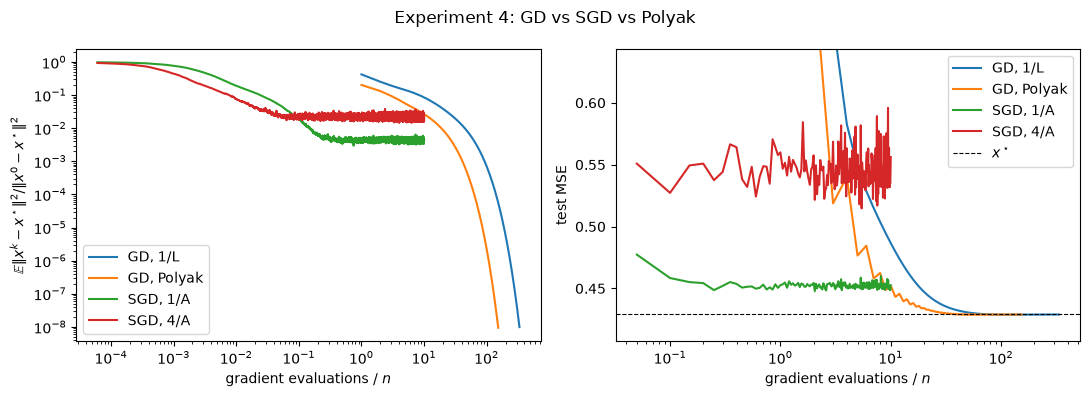

(err):  ||x^k - x*||^2 <= 0.01 ||x^0 - x*||^2;   (test): test MSE <= 1.1 x test MSE(x*) = 0.4719

method         |                    (err)                    |                   (test)                    | time / step
--------------------------------------------------------------------------------------------------------------------------
GD, 1/L        |       45 steps,    743040 grads,     6.9 ms |       13 steps,    214656 grads,     2.5 ms |    154.0 us
GD, Polyak     |       19 steps,    313728 grads,     4.9 ms |        7 steps,    115584 grads,     1.7 ms |    255.8 us
SGD, 1/(4A)    |     8747 steps,      8747 grads,    73.9 ms |     2576 steps,      2576 grads,    23.1 ms |      8.5 us
SGD, 1/(2A)    |     4564 steps,      4564 grads,    36.5 ms |     1281 steps,      1281 grads,    11.2 ms |      8.0 us
SGD, 1/A       |     2162 steps,      2162 grads,    18.2 ms |      682 steps,       682 grads,     6.2 ms |      8.4 us
SGD, 2/A       |     1067 steps,      1067 grads,    

In [30]:
EPOCHS = 10
RUNS5 = 50
REC = N // 20
methods = {
    "GD, 1/L": ("gd", gd_const),
    "GD, Polyak": ("gd", gd_pol),
    "SGD, 1/A": ("sgd", sgd(sgd_constant(1 / A), EPOCHS * N, runs=RUNS5, record=REC)),
    "SGD, 4/A": ("sgd", sgd(sgd_constant(4 / A), EPOCHS * N, runs=RUNS5, record=REC)),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (kind, h) in methods.items():
    if kind == "gd":
        ep = np.arange(len(h["err"]))                       # one epoch per GD step
        axes[0].loglog(ep[1:], h["err"][1:] / R0, label=name)
        axes[1].semilogx(ep[1:], h["test"][1:], label=name)
    else:
        ep = np.arange(len(h["err"])) / N
        axes[0].loglog(ep[1:], h["err"][1:] / R0, label=name)
        axes[1].semilogx(h["k"][1:] / N, h["test"][1:], label=name)
axes[1].axhline(MSE_TEST_STAR, ls="--", color="k", lw=0.8, label=r"$x^\star$")
axes[0].set_ylabel(r"$\mathbb{E}\|x^k-x^\star\|^2 / \|x^0-x^\star\|^2$")
axes[1].set_ylabel("test MSE")
axes[1].set_ylim(MSE_TEST_STAR * 0.95, MSE_TEST_STAR * 1.5)
for ax in axes:
    ax.set_xlabel("gradient evaluations / $n$")
    ax.legend()
fig.suptitle("Experiment 4: GD vs SGD vs Polyak")
save(fig, "cal_exp4_comparison.png")

print(f"(err):  ||x^k - x*||^2 <= {TOL_ERR:g} ||x^0 - x*||^2;   "
      f"(test): test MSE <= {TOL_TEST:g} x test MSE(x*) = {TOL_TEST * MSE_TEST_STAR:.4f}\n")
print(f"{'method':14s} | {'(err)':^43s} | {'(test)':^43s} | {'time / step':>11s}")
print("-" * 122)
for name, res in RESULTS.items():
    any_hit = res["err"] or res["test"]
    per_step = f"{1e6 * any_hit[2] / any_hit[0]:8.1f} us" if any_hit else ""
    print(f"{name:14s} | {fmt(res['err'])} | {fmt(res['test'])} | {per_step:>11s}")